> **A CHEM 438 final project from fall 2025**, shared as an example with the author's name removed. It used the student's own IP1 dose-response measurements. The data files are not included, so the cells will not rerun here: read it top to bottom, the figures and results are saved in the notebook.


In [83]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Effect of changes in concentration range of L-ATRP on the EC50 values in IP1 experiments on ATRPR1

## Introduction

In living organisms, protein synthesis is a stepwise process involving transcription and translation. The end product is a polypeptide chain made of amino acids linked by covalent peptide bonds which undergoes folding to form a functional protein. For functional specificity and other biological factors, mature proteins undergo post translational modifications(PTM) such as phosphorylation, acetylation, methylation and L-D amino acid isomerization among others.

## Background

### L-D isomerization

L-D isomerization is a PTM that results in the change in stereochemistry of  amino acid(s) in a peptide from the naturally occurring L-form to a D-form. This PTM has been observed in neuropeptides isolated from living organisms such as sea slugs, platypus and frogs. L/D isomerization has enormous effect on stability, biological function and receptor binding activity of these neuropeptides called D-amino acid containing peptides. In *Aplysia californica*, two peptide(both L/D forms) systems(achatin and allatotropin) with their cognate receptors have been established.

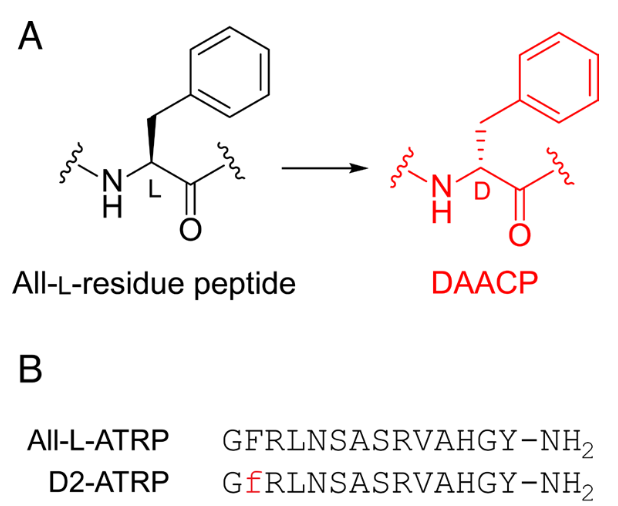

In [84]:
# importing image.
from IPython.display import Image, display
image_path = "L-D isomerization.png"
img = Image(filename=image_path, width=500, height=500)
display(img)

### Allatotropin peptide system

In the allatotropin system, L-D isomerization modulates receptor selectivity between both diastereomers. The all L-form is more potent on apATRPR1 and less potent on apATRPR2. The DAACP is more potent on apATRPR2 and less potent on apATRPR1.


*   L-ATRP: GFRLNSASRVAHGY-NH2
*   D2-ATRP: GfRLNSASVAHGY-NH2



### Structure of apATRPR1

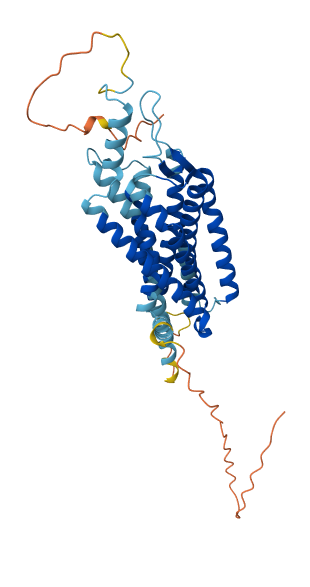

In [85]:
# importing image.
from IPython.display import Image, display
image_path = "apATRPR1.png"
img = Image(filename=image_path, width=500, height=500)
display(img)

### Structure of apATRPR2

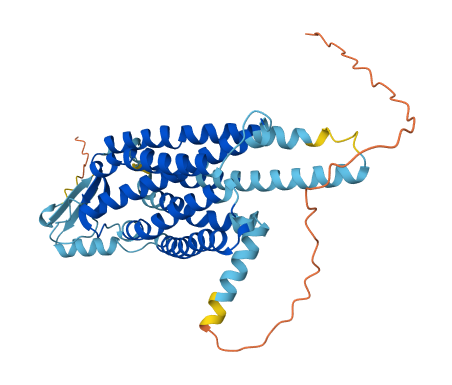

In [86]:
# importing image.
from IPython.display import Image, display
image_path = "apATRPR2.png"
img = Image(filename=image_path, width=500, height=500)
display(img)

### Typical IP1 experiment

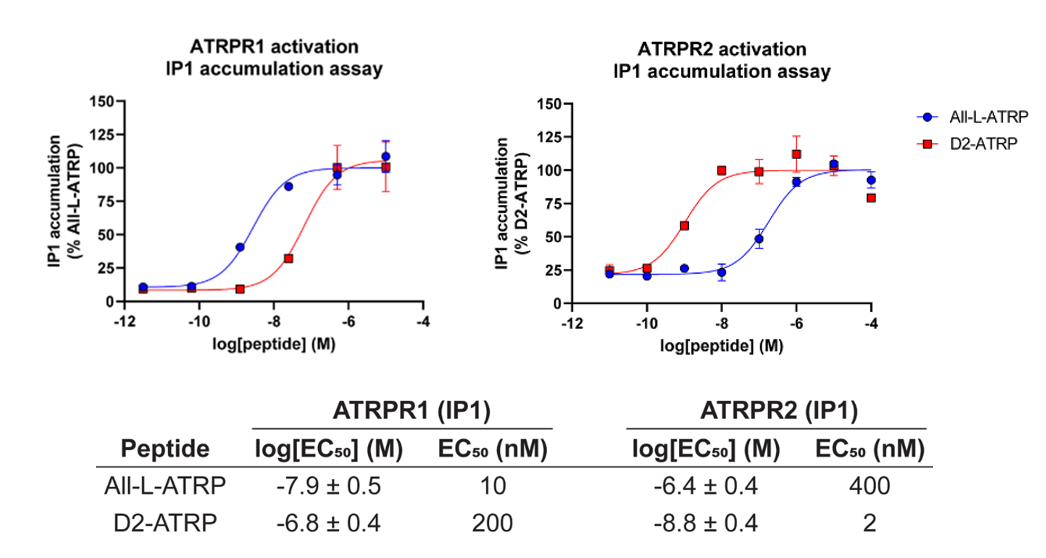

In [87]:
# importing image.
from IPython.display import Image, display
image_path = "ATRPR activation.png"
img = Image(filename=image_path, width=500, height=500)
display(img)

## Hypothesis

In dose response experiments such as above, the range of peptide concentrations tested on receptors are chosen arbitrarily while ensuring that the amount of IP1 elicited falls within the range of standards. The reported logEC50 and EC50 values are therefore dependent on the range of peptide/ligand concentrations and can be regarded as  variable values rather than constants. In this study, I intend to demonstrate that the EC50 value of L-ATRP  changes with varying concentration ranges in a typical IP1 experiment. This will be accomplished by using data from three different institutions(UNL, Purdue and Stanford) where the same experiment was carried using different ligand concentration ranges.

## Plan of study

- Organization of data
- Generation of a standard curve to obtain best of fit values(top, bottom, Hill, logIC50 and IC50)
- Conversion of 665/620 ratio into amount of IP1 produced

## Data set

In [88]:
df = pd.read_csv("Dataset_abridged.csv")

In [89]:
df

,Sample,Campus,Conc.,log(Conc),R1-665,R2-665,R1-620,R2-620,Ratio_1,Ratio_2,665/620
0,Standard,UNO,11000.000000,4.04,159,159,6112,6112,0.026014,0.026014,0.026014
1,Standard,UNO,2750.000000,3.44,249,249,6039,6039,0.041232,0.041232,0.041232
2,Standard,UNO,687.500000,2.84,502,502,5692,5692,0.088194,0.088194,0.088194
3,Standard,UNO,171.875000,2.24,1048,1048,5129,5129,0.204328,0.204328,0.204328
4,Standard,UNO,42.968750,1.63,1314,1314,4469,4469,0.294026,0.294026,0.294026
5,Standard,UNO,10.742188,1.03,1374,1374,4112,4112,0.334144,0.334144,0.334144
6,Standard,UNO,2.685547,0.43,1500,1500,4129,4129,0.363284,0.363284,0.363284
7,Standard,UNO,0.671387,-0.17,1493,1493,3928,3928,0.380092,0.380092,0.380092
8,L-ATRP,UNL,50.000000,1.70,596,644,4800,5303,0.124167,0.134167,0.129167
9,L-ATRP,UNL,5.000000,0.70,611,629,4957,5055,0.123260,0.126891,0.125076


In [90]:
df_standard = df.query("Sample == 'Standard'")
df_standard

,Sample,Campus,Conc.,log(Conc),R1-665,R2-665,R1-620,R2-620,Ratio_1,Ratio_2,665/620
0,Standard,UNO,11000.000000,4.04,159,159,6112,6112,0.026014,0.026014,0.026014
1,Standard,UNO,2750.000000,3.44,249,249,6039,6039,0.041232,0.041232,0.041232
2,Standard,UNO,687.500000,2.84,502,502,5692,5692,0.088194,0.088194,0.088194
3,Standard,UNO,171.875000,2.24,1048,1048,5129,5129,0.204328,0.204328,0.204328
4,Standard,UNO,42.968750,1.63,1314,1314,4469,4469,0.294026,0.294026,0.294026
5,Standard,UNO,10.742188,1.03,1374,1374,4112,4112,0.334144,0.334144,0.334144
6,Standard,UNO,2.685547,0.43,1500,1500,4129,4129,0.363284,0.363284,0.363284
7,Standard,UNO,0.671387,-0.17,1493,1493,3928,3928,0.380092,0.380092,0.380092


### Standard curve

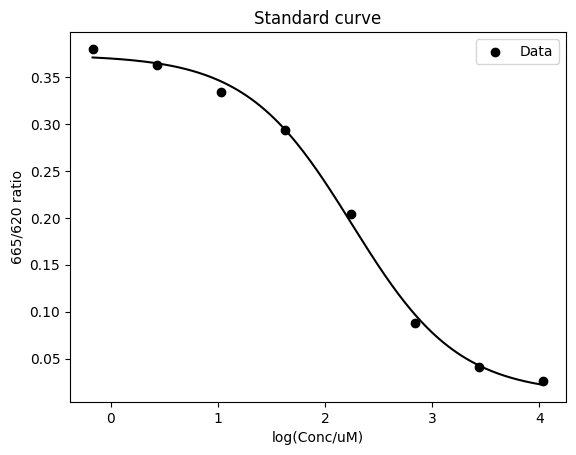

Bottom: 0.0123
Top: 0.3737
logIC50: 2.2526
Hill slope: -0.8771
IC50(uM): 178.90


In [91]:
# For standard curve
# Data
log_conc = np.array([4.04, 3.44, 2.84, 2.24, 1.63, 1.03, 0.43, -0.17])
ratio = np.array([0.026014, 0.041232, 0.088194, 0.204328,
                  0.294026, 0.334144, 0.363284, 0.380092])

def four_parameters(x, Bottom, Top, IC50, Hill):
    return Bottom + (Top - Bottom) / (1 + (10**(x - IC50))**Hill)


initial_values = [0.02, 0.4, 2.0, 1.0]

# Curve fit
params, cov = curve_fit(four_parameters, log_conc, ratio, p0=initial_values)
Bottom, Top, IC50, Hill = params

x_fit = np.linspace(min(log_conc), max(log_conc), 200)
y_fit = four_parameters(x_fit, *params)

# Plot
plt.scatter(log_conc, ratio, color='black', label='Data')
plt.plot(x_fit, y_fit, color='black')
plt.xlabel('log(Conc/uM)')
plt.ylabel('665/620 ratio')
plt.title('Standard curve')
plt.legend()
plt.show()

# Best of fit values
print(f"Bottom: {Bottom:.4f}")
print(f"Top: {Top:.4f}")
print(f"logIC50: {IC50:.4f}")
print(f"Hill slope: {-Hill:.4f}")
print(f"IC50(uM): {10**IC50:.2f}")





### Conversion of ratio to [IP1]

### UNL - Range 1(50 - 0.0005(uM))

In [92]:
df_UNL = df.query("Campus == 'UNL'")
df_UNL

,Sample,Campus,Conc.,log(Conc),R1-665,R2-665,R1-620,R2-620,Ratio_1,Ratio_2,665/620
8,L-ATRP,UNL,50.0000,1.7,596,644,4800,5303,0.124167,0.134167,0.129167
9,L-ATRP,UNL,5.0000,0.7,611,629,4957,5055,0.123260,0.126891,0.125076
10,L-ATRP,UNL,0.5000,-0.3,703,684,4773,4816,0.147287,0.143306,0.145296
11,L-ATRP,UNL,0.0500,-1.3,720,846,4800,4981,0.150000,0.176250,0.163125
12,L-ATRP,UNL,0.0050,-2.3,972,1057,4276,4724,0.227315,0.247194,0.237254
13,L-ATRP,UNL,0.0005,-3.3,951,1007,4396,4159,0.216333,0.229072,0.222702


Estimated IP1 values: [522.70757287 554.77594914 417.30991908 329.55337019 127.38735484
 154.31814178]
logEC50(uM): -1.3000
EC50(uM): 0.0501


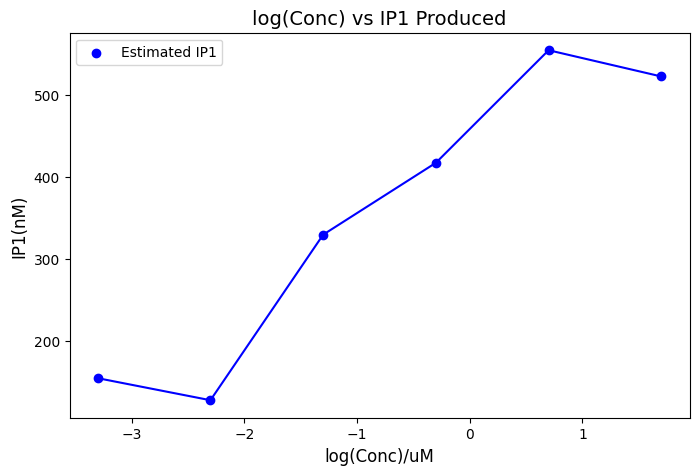

In [93]:
# Estimation of IP1 produced

# Data
log_conc = np.array([1.7, 0.7, -0.3, -1.3, -2.3, -3.3])
ratio = np.array([0.129167, 0.125076, 0.145296, 0.163125, 0.237254, 0.222702])

# Best of fit values
Bottom = 0.0123
Top = 0.3737
IC50 = 2.2526
Hill = 0.8771

# Formula for IP1
def compute_IP1(r):
    return (IC50 / (((Top - r) / (r - Bottom))**(1/-Hill)))*100

IP1_values = np.array([compute_IP1(r) for r in ratio])

# Plot [IP1] against log(Conc)
plt.figure(figsize=(8, 5))
plt.scatter(log_conc, IP1_values, color='blue', label="Estimated IP1")
plt.plot(log_conc, IP1_values, color='blue')
plt.xlabel('log(Conc)/uM', fontsize=12)
plt.ylabel('IP1(nM)', fontsize=12)
plt.title('log(Conc) vs IP1 Produced', fontsize=14)
plt.legend()


# Estimate EC50
max_ip1 = np.max(IP1_values)
half_max = max_ip1 / 2
idx = (np.abs(IP1_values - half_max)).argmin()
EC50_log = log_conc[idx]
EC50_conc = 10**EC50_log

print("Estimated IP1 values:", IP1_values)
print(f"logEC50(uM): {EC50_log:.4f}")
print(f"EC50(uM): {EC50_conc:.4f}")

### Purdue - Range 2 (20 - 0.0002(uM))

In [94]:
df_Purdue = df.query("Campus == 'Purdue'")
df_Purdue

,Sample,Campus,Conc.,log(Conc),R1-665,R2-665,R1-620,R2-620,Ratio_1,Ratio_2,665/620
14,L-ATRP,Purdue,20.0000,1.3,718,736,5100,5603,0.140784,0.144314,0.142549
15,L-ATRP,Purdue,2.0000,0.3,810,791,5257,5355,0.154080,0.150466,0.152273
16,L-ATRP,Purdue,0.2000,-0.7,827,953,5073,5116,0.163020,0.187857,0.175439
17,L-ATRP,Purdue,0.0200,-1.7,1079,1164,5100,5281,0.211569,0.228235,0.219902
18,L-ATRP,Purdue,0.0020,-2.7,1058,1114,4576,5024,0.231206,0.243444,0.237325
19,L-ATRP,Purdue,0.0002,-3.7,1063,1116,4696,4459,0.226363,0.237649,0.232006


Estimated IP1 values: [433.22405077 379.99732551 281.33835225 160.01038547 127.26598614
 136.2646075 ]
logEC50(uM): -1.7000
EC50(uM): 0.0200


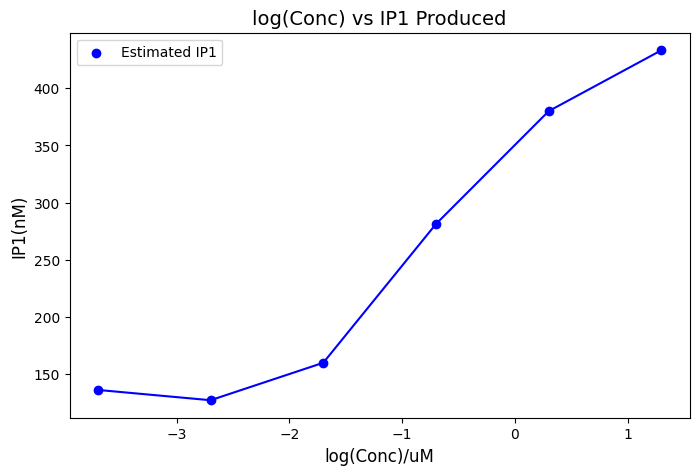

In [95]:
# Estimation of IP1 produced

# Data
log_conc = np.array([1.3, 0.3, -0.7, -1.7, -2.7, -3.7])
ratio = np.array([0.142549, 0.152273, 0.175439, 0.219902, 0.237325, 0.2322006])

# Best of fit values
Bottom = 0.0123
Top = 0.3737
IC50 = 2.2526
Hill = 0.8771

# Formula for IP1
def compute_IP1(r):
    return (IC50 / (((Top - r) / (r - Bottom))**(1/-Hill)))*100

IP1_values = np.array([compute_IP1(r) for r in ratio])

# Plot [IP1] against log(Conc)
plt.figure(figsize=(8, 5))
plt.scatter(log_conc, IP1_values, color='blue', label="Estimated IP1")
plt.plot(log_conc, IP1_values, color='blue')
plt.xlabel('log(Conc)/uM', fontsize=12)
plt.ylabel('IP1(nM)', fontsize=12)
plt.title('log(Conc) vs IP1 Produced', fontsize=14)
plt.legend()


# Estimate EC50
max_ip1 = np.max(IP1_values)
half_max = max_ip1 / 2
idx = (np.abs(IP1_values - half_max)).argmin()
EC50_log = log_conc[idx]
EC50_conc = 10**EC50_log

print("Estimated IP1 values:", IP1_values)
print(f"logEC50(uM): {EC50_log:.4f}")
print(f"EC50(uM): {EC50_conc:.4f}")

### Stanford - Range 3(10 - 0.0001(uM))

In [96]:
df_Stanford = df.query("Campus == 'Stanford'")
df_Stanford

,Sample,Campus,Conc.,log(Conc),R1-665,R2-665,R1-620,R2-620,Ratio_1,Ratio_2,665/620
20,L-ATRP,Stanford,10.0000,1.0,903,951,5700,6203,0.158421,0.166842,0.162632
21,L-ATRP,Stanford,1.0000,0.0,918,936,5857,5955,0.156736,0.159809,0.158272
22,L-ATRP,Stanford,0.1000,-1.0,1010,991,5673,5716,0.178036,0.174687,0.176362
23,L-ATRP,Stanford,0.0100,-2.0,1027,1153,5700,5881,0.180175,0.202281,0.191228
24,L-ATRP,Stanford,0.0010,-3.0,1279,1364,5176,5624,0.247102,0.263524,0.255313
25,L-ATRP,Stanford,0.0001,-4.0,1258,1314,5296,5059,0.237538,0.248112,0.242825


Estimated IP1 values: [331.66892563 351.07642047 278.05126437 230.35388612  99.2190979
 118.13332931]
logEC50(uM): -2.0000
EC50(uM): 0.0100


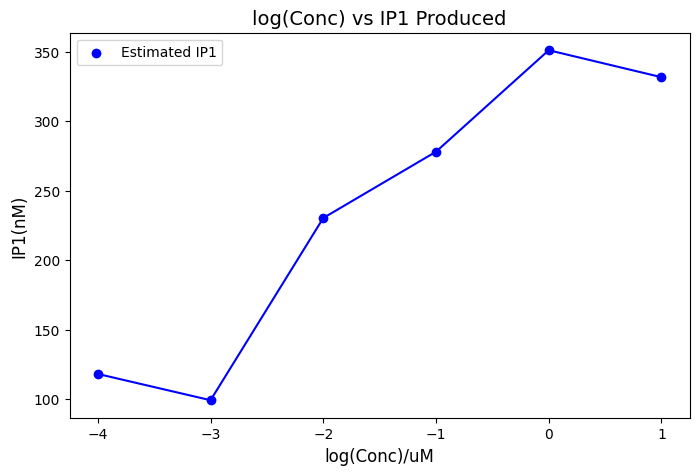

In [97]:
# Estimation of IP1 produced

# Data
log_conc = np.array([1.0, 0.0, -1.0, -2.0, -3.0, -4.0])
ratio = np.array([0.162632, 0.158272, 0.176362, 0.191228, 0.255313, 0.242825])

# Best of fit values
Bottom = 0.0123
Top = 0.3737
IC50 = 2.2526
Hill = 0.8771

# Formula for IP1
def compute_IP1(r):
    return (IC50 / (((Top - r) / (r - Bottom))**(1/-Hill)))*100

IP1_values = np.array([compute_IP1(r) for r in ratio])

# Plot [IP1] against log(Conc)
plt.figure(figsize=(8, 5))
plt.scatter(log_conc, IP1_values, color='blue', label="Estimated IP1")
plt.plot(log_conc, IP1_values, color='blue')
plt.xlabel('log(Conc)/uM', fontsize=12)
plt.ylabel('IP1(nM)', fontsize=12)
plt.title('log(Conc) vs IP1 Produced', fontsize=14)
plt.legend()


# Estimate EC50
max_ip1 = np.max(IP1_values)
half_max = max_ip1 / 2
idx = (np.abs(IP1_values - half_max)).argmin()
EC50_log = log_conc[idx]
EC50_conc = 10**EC50_log

print("Estimated IP1 values:", IP1_values)
print(f"logEC50(uM): {EC50_log:.4f}")
print(f"EC50(uM): {EC50_conc:.4f}")

## Summary of results

In [98]:
data = {
    'Canpus': ['UNL', 'Purdue', 'Stanford'],
    'logEC50(uM)': [-1.300, -1.700, -2.000],
    'EC50(uM)': [0.0501, 0.0200, 0.100]
}

In [99]:
pd.DataFrame(data)

,Canpus,logEC50(uM),EC50(uM)
0,UNL,-1.3,0.0501
1,Purdue,-1.7,0.0200
2,Stanford,-2.0,0.1000


The EC50 value is the concentration of ligand required to attain half of maximum response. In this instance it is the concentration of L-ATRP required to obtain half of the maximum amount of IP1. This number can be traced directly as the concentration of L-ATRP that concincides with half of the curve. From the analysis, ranges 0, 1, and 2 gave logEC50 values of -1.3uM, -1.7uM and -2.0uM respectively corresponding to EC50 values of 0.0501 uM, 0.0200 uM and 0.100 uM. Based on this it can be said that using a range with a higher relatively maximum concentration does not necessarily give a lower EC50 value since the EC50 value for the (20-0.0002uM) range was lower than the EC50 value for the (50-0.0005uM) range. Also, the lowest range range of (10 - 0.0001uM) gave the highest EC50 value indicating that in this setup a higher concentration is needed to obtain a maximum response.

## Conclusion

From the study, it can be concluded that EC50 values in such dose response experiments are variables and not constants. This is because such reported values are highly affected by experimental conditions such the range of ligand(peptide) concentrations deployed to be tested on a receptor. As such, in designing such experiments, care should be taken in deciding on the range of ligand concentrations that would be used.